In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())
from common import *

import matplotlib.pyplot as plt
import seaborn as sns
os.makedirs("figures", exist_ok=True)
print(os.getcwd())

C:\Users\mansi\Documents\ai-grid-fault-classifier


In [2]:
df = load_clean()
print(df.shape)
print(df[TARGET].value_counts())

(134019, 14)
fault_types
LG      22337
LLG     22337
LLL     22337
LLLG    22337
NF      22337
LL      22334
Name: count, dtype: int64


In [3]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())
from common import *

import matplotlib.pyplot as plt
import seaborn as sns
os.makedirs("figures", exist_ok=True)

df = load_clean()
print(os.getcwd())
print(df.shape)

C:\Users\mansi\Documents\ai-grid-fault-classifier
(134019, 14)


In [4]:
!git branch

* m2-viz
  main


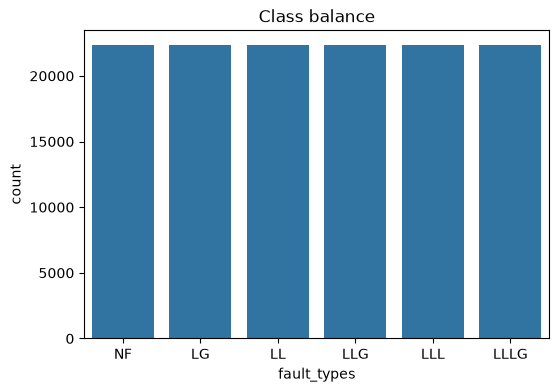

In [5]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x=TARGET, order=CLASSES)
plt.title("Class balance")
plt.savefig("figures/class_balance.png", dpi=200, bbox_inches="tight")
plt.show()

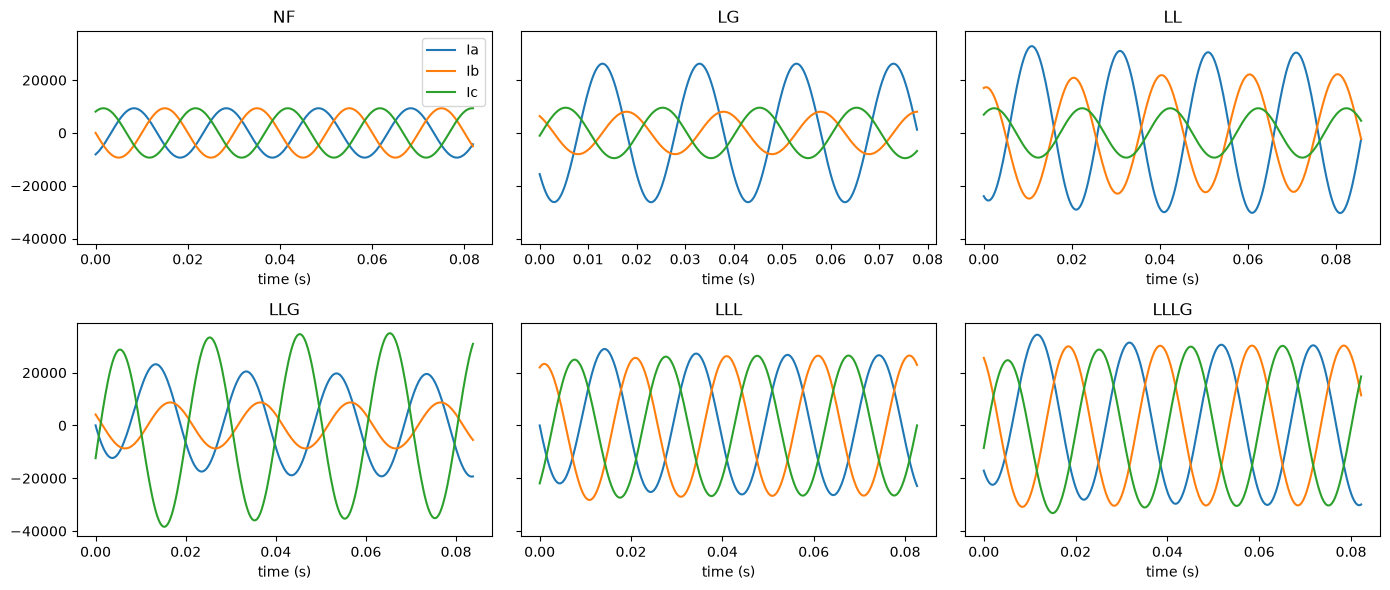

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, c in zip(axes.ravel(), CLASSES):
    g = df[df[TARGET] == c].iloc[:330]          # about 4 cycles at 50 Hz
    t = g["time_stamp"] - g["time_stamp"].iloc[0]
    for col in ["Ia", "Ib", "Ic"]:
        ax.plot(t, g[col], label=col)
    ax.set_title(c)
    ax.set_xlabel("time (s)")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("figures/waveforms_current.png", dpi=200)
plt.show()

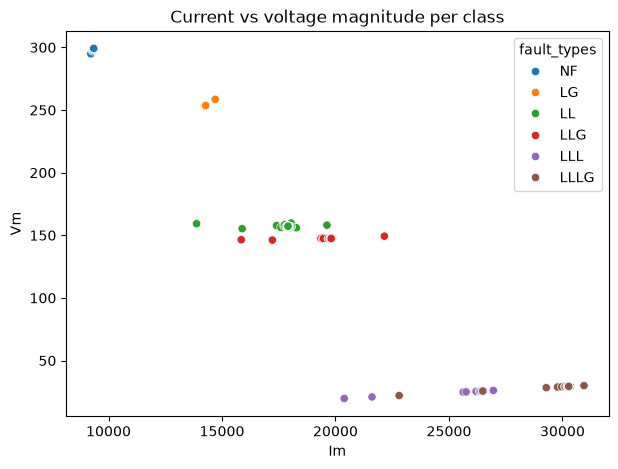

In [7]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df.iloc[::20], x="Im", y="Vm", hue=TARGET, hue_order=CLASSES)
plt.title("Current vs voltage magnitude per class")
plt.savefig("figures/scatter_Im_Vm.png", dpi=200, bbox_inches="tight")
plt.show()